# 01 · EDA · Home Credit Default Risk
Objetivo: entender datos y derivar decisiones de preprocesamiento para `src/features.py`.

In [1]:
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score
from src.config import seed_everything, TARGET, ID_COL
from src.data import load_data
seed_everything(); sns.set_theme(style='whitegrid'); pd.set_option('display.max_columns', 50)
train, test, sample = load_data()
print(train.shape, test.shape)

(171202, 34) (61500, 33)


## 1. Target

TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64


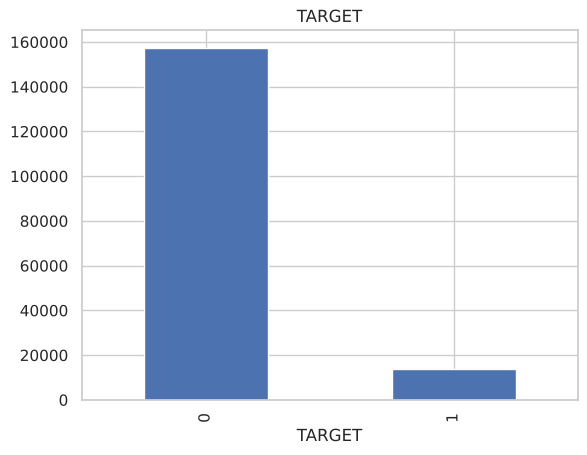

In [2]:
print(train[TARGET].value_counts(normalize=True).round(4))
train[TARGET].value_counts().plot.bar(title='TARGET'); plt.show()

Desbalanceado (~8% positivos). AUC no se ve afectado por el umbral; usar **StratifiedKFold**.

## 2. Tipos y valores faltantes (train vs test)

In [3]:
info = pd.DataFrame({'dtype': train.dtypes.astype(str), 'nunique': train.nunique(),
    'na_train': train.isna().mean(), 'na_test': test.reindex(columns=train.columns).isna().mean()})
info.sort_values('na_train', ascending=False).head(12)

,dtype,nunique,na_train,na_test
EXT_SOURCE_1,float64,49131,0.694665,0.697756
OWN_CAR_AGE,float64,54,0.659992,0.665187
EXT_SOURCE_3,float64,784,0.318840,0.320163
AMT_REQ_CREDIT_BUREAU_MON,float64,21,0.135022,0.138423
AMT_REQ_CREDIT_BUREAU_QRT,float64,11,0.135022,0.138423
AMT_REQ_CREDIT_BUREAU_HOUR,float64,5,0.135022,0.138423
AMT_REQ_CREDIT_BUREAU_YEAR,float64,23,0.135022,0.138423
EXT_SOURCE_2,float64,90952,0.002155,0.002114
CNT_FAM_MEMBERS,float64,15,0.000012,0.000000
SK_ID_CURR,int64,171202,0.000000,0.000000


## 3. Variables categóricas: frecuencia y tasa de default

In [4]:
cats = train.select_dtypes(include=['object','string']).columns.tolist()
for c in cats:
    t = train.groupby(c, dropna=False)[TARGET].agg(['size','mean']).sort_values('size', ascending=False)
    print(f'\n== {c} ({train[c].nunique()} niveles)'); print(t.head(8).round(3))


== NAME_CONTRACT_TYPE (2 niveles)
                      size   mean
NAME_CONTRACT_TYPE               
Cash loans          154988  0.083
Revolving loans      16214  0.056

== CODE_GENDER (3 niveles)
               size   mean
CODE_GENDER               
F            112549  0.070
M             58649  0.101
XNA               4  0.000

== NAME_INCOME_TYPE (8 niveles)
                       size   mean
NAME_INCOME_TYPE                  
Working               88268  0.095
Commercial associate  40007  0.075
Pensioner             30895  0.054
State servant         12007  0.059
Unemployed               10  0.200
Student                   9  0.000
Maternity leave           3  0.333
Businessman               3  0.000

== NAME_EDUCATION_TYPE (5 niveles)
                                 size   mean
NAME_EDUCATION_TYPE                         
Secondary / secondary special  121612  0.089
Higher education                41645  0.054
Incomplete higher                5711  0.087
Lower secondary       

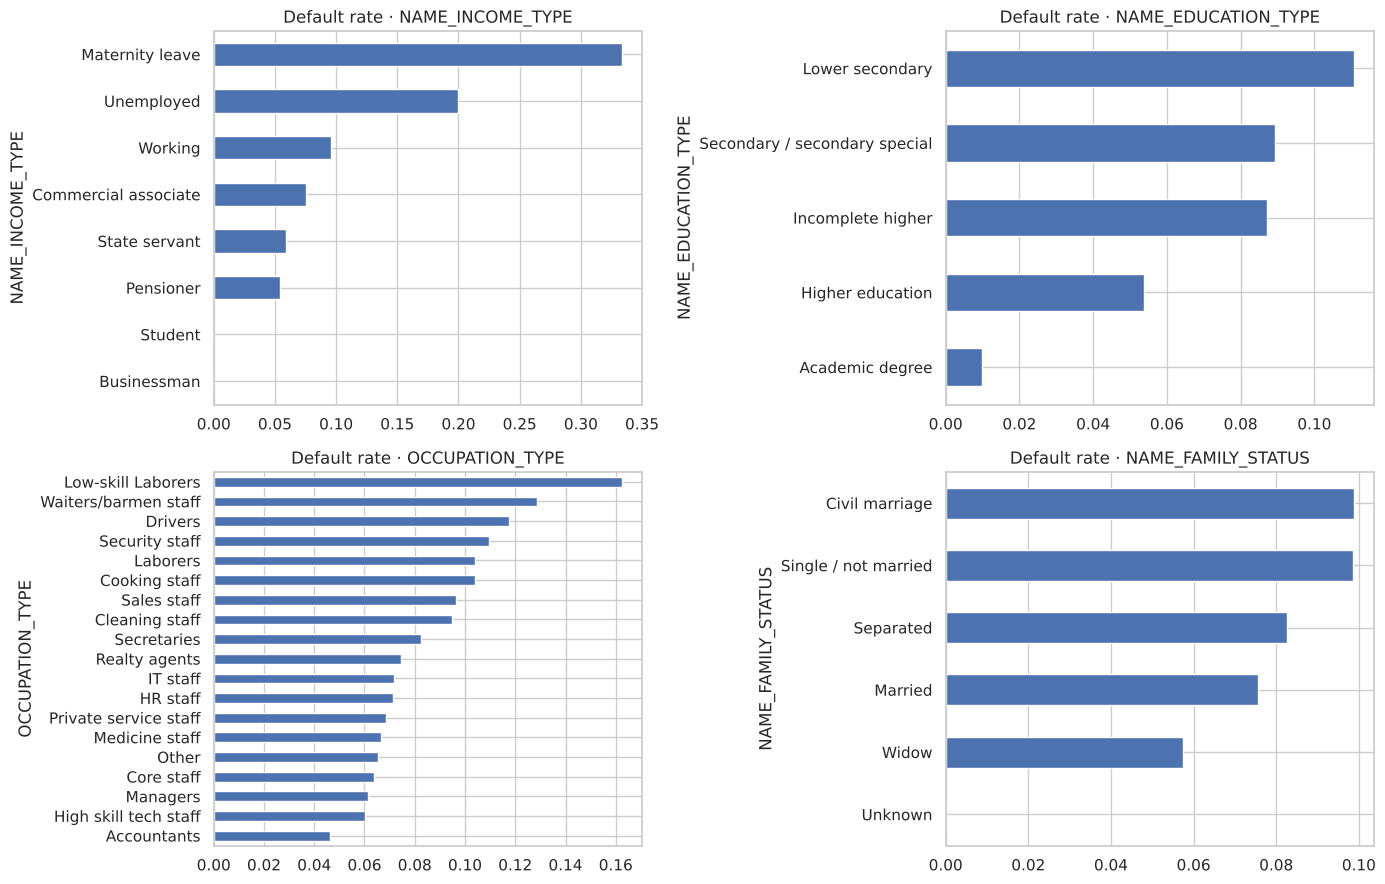

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, c in zip(axes.ravel(), ['NAME_INCOME_TYPE','NAME_EDUCATION_TYPE','OCCUPATION_TYPE','NAME_FAMILY_STATUS']):
    train.groupby(c)[TARGET].mean().sort_values().plot.barh(ax=ax, title=f'Default rate · {c}')
plt.tight_layout(); plt.show()

## 4. Numéricas: AUC univariada (señal individual)

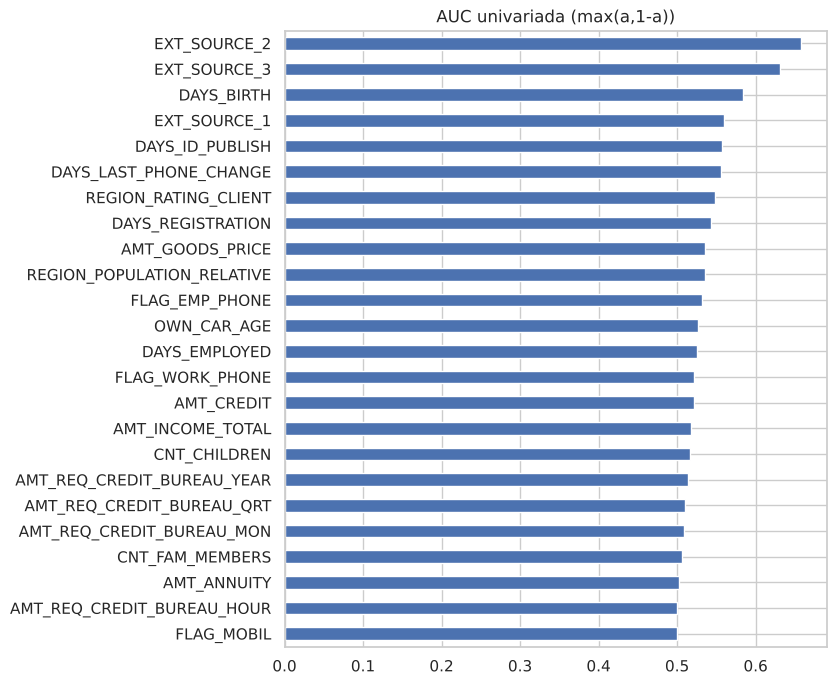

EXT_SOURCE_2                  0.6580
EXT_SOURCE_3                  0.6313
DAYS_BIRTH                    0.5844
EXT_SOURCE_1                  0.5601
DAYS_ID_PUBLISH               0.5568
DAYS_LAST_PHONE_CHANGE        0.5565
REGION_RATING_CLIENT          0.5481
DAYS_REGISTRATION             0.5426
AMT_GOODS_PRICE               0.5359
REGION_POPULATION_RELATIVE    0.5350
dtype: float64

In [6]:
nums = [c for c in train.select_dtypes('number').columns if c not in (ID_COL, TARGET)]
auc = {c: roc_auc_score(train[TARGET], train[c].fillna(train[c].median())) for c in nums}
auc = pd.Series(auc).apply(lambda a: max(a, 1-a)).sort_values(ascending=False)
auc.plot.barh(figsize=(7, 8), title='AUC univariada (max(a,1-a))'); plt.gca().invert_yaxis(); plt.show()
auc.head(10).round(4)

## 5. EXT_SOURCE_*: las más predictivas

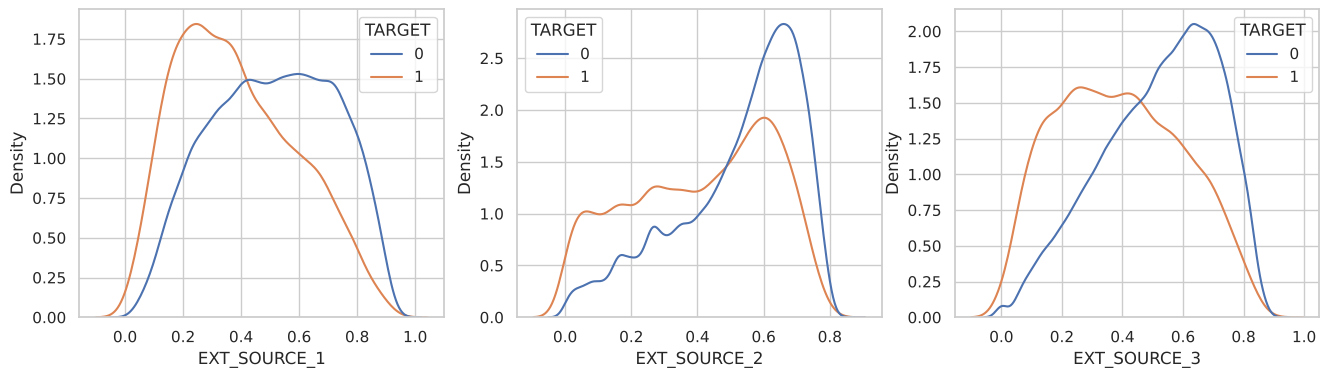

Default rate por # de EXT faltantes:
    size   mean
0  36164  0.071
1  96310  0.080
2  38611  0.091
3    117  0.094
AUC media EXT: 0.7059


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']):
    sns.kdeplot(data=train, x=c, hue=TARGET, common_norm=False, ax=ax)
plt.show()
ext = train[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']]
print('Default rate por # de EXT faltantes:'); print(train.groupby(ext.isna().sum(axis=1))[TARGET].agg(['size','mean']).round(3))
print('AUC media EXT:', round(1-roc_auc_score(train[TARGET], ext.mean(axis=1).fillna(0.5)), 4))

## 6. Anomalías

In [8]:
print('DAYS_EMPLOYED == 365243:', (train.DAYS_EMPLOYED==365243).mean().round(3))
print(train.groupby(train.DAYS_EMPLOYED==365243)[TARGET].mean().round(4))
print(pd.crosstab(train.DAYS_EMPLOYED==365243, train.NAME_INCOME_TYPE))

DAYS_EMPLOYED == 365243: 0.18
DAYS_EMPLOYED
False    0.0866
True     0.0542
Name: TARGET, dtype: float64
NAME_INCOME_TYPE  Businessman  Commercial associate  Maternity leave  \
DAYS_EMPLOYED                                                          
False                       3                 40007                3   
True                        0                     0                0   

NAME_INCOME_TYPE  Pensioner  State servant  Student  Unemployed  Working  
DAYS_EMPLOYED                                                             
False                     7          12007        9           0    88268  
True                  30888              0        0          10        0  


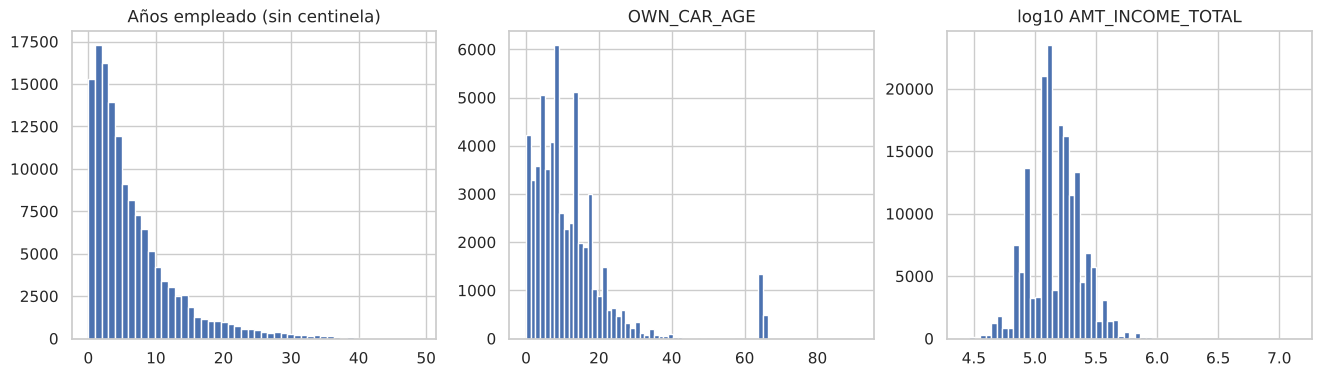

OWN_CAR_AGE >= 60: 1826 | default rate 0.089
CODE_GENDER XNA: 4 | ORGANIZATION_TYPE XNA: 30898
XNA org ~ pensionistas: 1.0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
train.loc[train.DAYS_EMPLOYED!=365243, 'DAYS_EMPLOYED'].div(-365).hist(bins=50, ax=axes[0]); axes[0].set_title('Años empleado (sin centinela)')
train.OWN_CAR_AGE.hist(bins=70, ax=axes[1]); axes[1].set_title('OWN_CAR_AGE')
np.log10(train.AMT_INCOME_TOTAL).hist(bins=60, ax=axes[2]); axes[2].set_title('log10 AMT_INCOME_TOTAL')
plt.show()
print('OWN_CAR_AGE >= 60:', (train.OWN_CAR_AGE>=60).sum(), '| default rate', train.loc[train.OWN_CAR_AGE>=60, TARGET].mean().round(3))
print('CODE_GENDER XNA:', (train.CODE_GENDER=='XNA').sum(), '| ORGANIZATION_TYPE XNA:', (train.ORGANIZATION_TYPE=='XNA').sum())
print('XNA org ~ pensionistas:', (train.ORGANIZATION_TYPE=='XNA').eq(train.DAYS_EMPLOYED==365243).mean().round(4))

## 7. Edad y ratios financieros

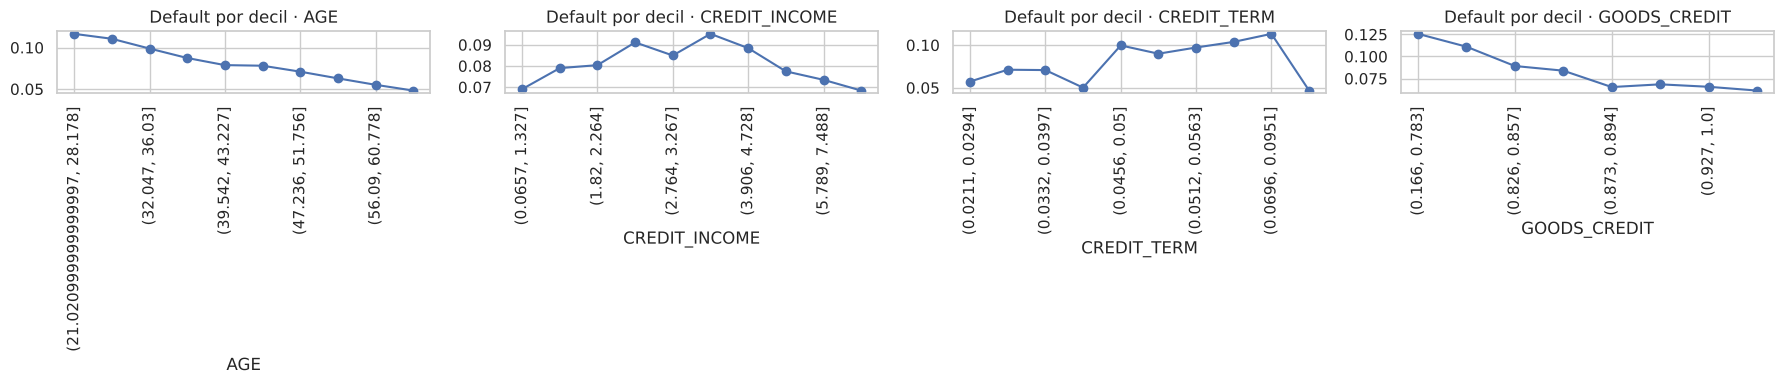

CREDIT_INCOME 0.5045
CREDIT_TERM 0.5336
GOODS_CREDIT 0.5681


In [10]:
tmp = train.assign(AGE=-train.DAYS_BIRTH/365, CREDIT_INCOME=train.AMT_CREDIT/train.AMT_INCOME_TOTAL,
                   CREDIT_TERM=train.AMT_ANNUITY/train.AMT_CREDIT, GOODS_CREDIT=train.AMT_GOODS_PRICE/train.AMT_CREDIT)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ['AGE','CREDIT_INCOME','CREDIT_TERM','GOODS_CREDIT']):
    tmp.groupby(pd.qcut(tmp[c], 10, duplicates='drop'), observed=True)[TARGET].mean().plot(ax=ax, marker='o', title=f'Default por decil · {c}')
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()
for c in ['CREDIT_INCOME','CREDIT_TERM','GOODS_CREDIT']:
    a = roc_auc_score(tmp[TARGET], tmp[c]); print(c, round(max(a,1-a),4))

## 8. Correlaciones entre numéricas

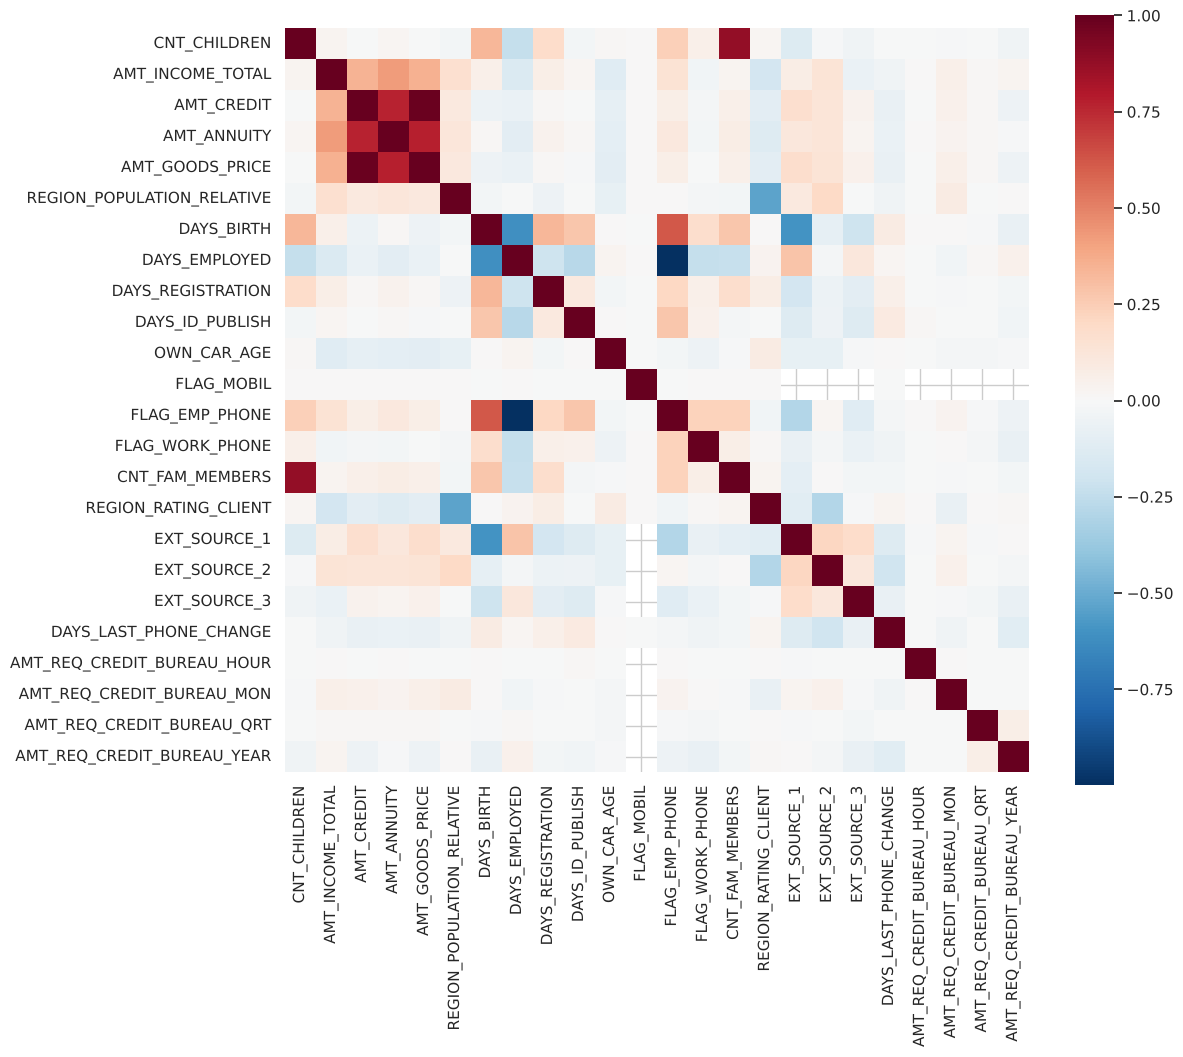

DAYS_EMPLOYED  FLAG_EMP_PHONE     1.000
AMT_CREDIT     AMT_GOODS_PRICE    0.987
CNT_CHILDREN   CNT_FAM_MEMBERS    0.879
AMT_ANNUITY    AMT_GOODS_PRICE    0.776
AMT_CREDIT     AMT_ANNUITY        0.772
DAYS_BIRTH     FLAG_EMP_PHONE     0.620
               DAYS_EMPLOYED      0.616
               EXT_SOURCE_1       0.599
dtype: float64

In [11]:
corr = train[nums].corr()
plt.figure(figsize=(12, 10)); sns.heatmap(corr, cmap='RdBu_r', center=0, square=True); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().abs().sort_values(ascending=False)
pairs.head(8).round(3)

## 9. Drift train vs test (adversarial validation)

In [12]:
import lightgbm as lgb
from sklearn.model_selection import cross_val_score
X = pd.concat([train.drop(columns=[TARGET]), test]).drop(columns=[ID_COL])
for c in cats: X[c] = X[c].astype('category')
y = np.r_[np.zeros(len(train)), np.ones(len(test))]
adv = cross_val_score(lgb.LGBMClassifier(n_estimators=200, random_state=42, verbose=-1), X, y, cv=3, scoring='roc_auc')
print('Adversarial AUC:', adv.mean().round(4), '(≈0.5 = sin drift)')

Adversarial AUC: 0.5116 (≈0.5 = sin drift)


## 10. Conclusiones → `src/features.py`
- **EXT_SOURCE_1/2/3** dominan la señal; agregados (media, std, producto, # faltantes) aportan.
- **DAYS_EMPLOYED = 365243** (≈18%) es centinela de pensionistas/desempleados → NaN + flag `DAYS_EMPLOYED_ANOM`.
- **XNA** en `CODE_GENDER` / `ORGANIZATION_TYPE` → NaN (XNA de organización coincide 100% con el centinela).
- Redundantes: `FLAG_EMP_PHONE` ≡ centinela, `AMT_CREDIT`~`AMT_GOODS_PRICE` (0.99), `CNT_CHILDREN`~`CNT_FAM_MEMBERS`.
- `OCCUPATION_TYPE` ya trae los faltantes como 'Other'.
- `OWN_CAR_AGE` ≥ 60 y `AMT_INCOME_TOTAL` extremo: outliers; con árboles no requieren tratamiento, revisar si se prueban modelos lineales.
- Ratios financieros (crédito/ingreso, anualidad/crédito, bienes/crédito) tienen señal no lineal.
- Sin drift train/test (adversarial AUC ≈ 0.51) → **StratifiedKFold** es válido y el CV debería seguir al leaderboard.